# Task-1

In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import shap
import time

from sklearn.model_selection import train_test_split
from sklearn.inspection import permutation_importance
from sklearn.metrics import roc_auc_score
from xgboost import XGBClassifier
from sklearn.inspection import PartialDependenceDisplay
from sklearn.base import clone

In [2]:

# Load the Titanic dataset
df = pd.read_csv("titanic.csv")

In [3]:
df

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
886,0,2,male,27.0,0,0,13.0000,S,Second,man,True,NaN,Southampton,no,True
887,1,1,female,19.0,0,0,30.0000,S,First,woman,False,B,Southampton,yes,True
888,0,3,female,NaN,1,2,23.4500,S,Third,woman,False,NaN,Southampton,no,False
889,1,1,male,26.0,0,0,30.0000,C,First,man,True,C,Cherbourg,yes,True


In [4]:
# Convert column names to lowercase and remove extra spaces
df.columns = df.columns.str.strip().str.lower()

In [5]:
# Display column names
df.columns

Index(['survived', 'pclass', 'sex', 'age', 'sibsp', 'parch', 'fare',
       'embarked', 'class', 'who', 'adult_male', 'deck', 'embark_town',
       'alive', 'alone'],
      dtype='str')

In [6]:
# Fill missing ages using the median of each passenger class and sex group
df["age"] = df.groupby(["pclass", "sex"])["age"].transform(
    lambda group: group.fillna(group.median())
)

In [7]:
# Fill any remaining missing ages with the overall median
df["age"] = df["age"].fillna(df["age"].median())

In [8]:
# Fill missing fare values with the median
df["fare"] = df["fare"].fillna(df["fare"].median())

In [9]:
# Convert sex into a numeric feature
df["sex_male"] = (df["sex"] == "male").astype(int)

In [10]:
# Select the required features
features = ["pclass", "sex_male", "age", "sibsp", "parch", "fare"]
target = "survived"


In [11]:
X = df[features]
y = df[target]

In [12]:
X.shape

(891, 6)

In [13]:
y.shape

(891,)

In [14]:
# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Create the XGBoost model
model = XGBClassifier(
    n_estimators=300,
    learning_rate=0.1,
    max_depth=3,
    random_state=42,
    eval_metric="logloss"
)

# Train the model
model.fit(X_train, y_train)

# Predict survival probabilities for the test set
y_prob = model.predict_proba(X_test)[:, 1]

# Calculate test AUC
test_auc = roc_auc_score(y_test, y_prob)

print("Test AUC:", round(test_auc, 4))

Test AUC: 0.8274


In [15]:
# Calculate permutation importance on the test set
perm_result = permutation_importance(
    model,
    X_test,
    y_test,
    n_repeats=20,
    scoring="roc_auc",
    random_state=42,
    n_jobs=-1
)

# Create a table of feature importance
importance_df = pd.DataFrame({
    "Feature": X_test.columns,
    "Importance": perm_result.importances_mean
})

# Sort from most important to least important
importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
).reset_index(drop=True)

importance_df

,Feature,Importance
0,sex_male,0.217240
1,pclass,0.101775
2,age,0.046469
3,fare,0.026528
4,sibsp,0.026479
5,parch,0.005919


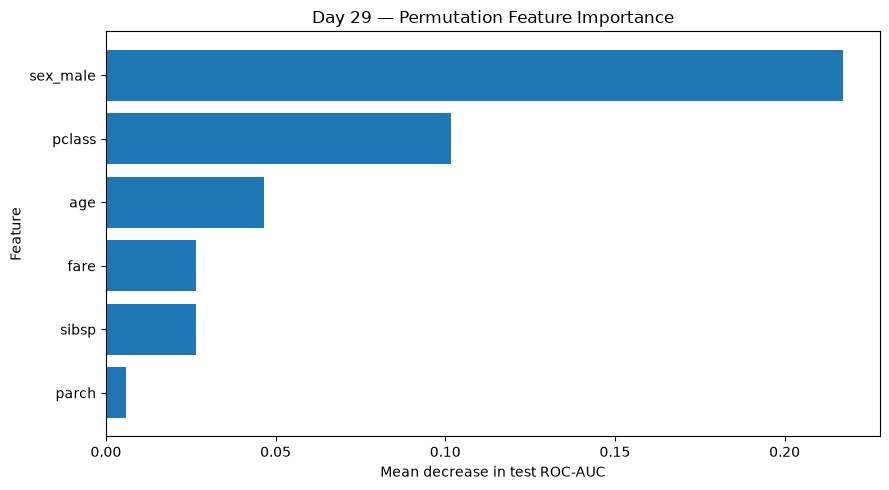

In [16]:
plt.figure(figsize=(9, 5))

plt.barh(
    importance_df["Feature"],
    importance_df["Importance"]
)

plt.xlabel("Mean decrease in test ROC-AUC")
plt.ylabel("Feature")
plt.title("Day 29 — Permutation Feature Importance")
plt.gca().invert_yaxis()

plt.tight_layout()
plt.show()

## Global Interpretation

### Top Three Features

According to permutation importance on the test dataset, the three most important features are:

1. **sex_male — 0.217240:** Shuffling this feature caused the largest decrease in test ROC-AUC.
2. **pclass — 0.101775:** Shuffling passenger class also reduced the model's test ROC-AUC.
3. **age — 0.046469:** Shuffling age caused the third-largest decrease in test ROC-AUC.

These results suggest that the model relies most on passenger sex, followed by passenger class and age, when distinguishing between passengers who survived and those who did not.

### What the Ranking Cannot Answer

Permutation importance shows how much each feature contributes to overall predictive performance, but it cannot explain why the model predicted survival or death for a particular passenger. For an individual prediction, I would use SHAP values to examine how each feature pushes the model's prediction up or down.

# Task-2

In [17]:
# Create a SHAP TreeExplainer for the trained XGBoost model
explainer = shap.TreeExplainer(model)

# Calculate SHAP values for the test dataset
shap_values = explainer.shap_values(X_test)

# Get the model's raw prediction output
raw = model.predict(X_test, output_margin=True)

# Display the shapes
print("SHAP values shape:", np.shape(shap_values))
print("Raw output shape:", np.shape(raw))

# Display the base value
print("Expected value:", explainer.expected_value)


SHAP values shape: (179, 6)
Raw output shape: (179,)
Expected value: -0.48469374


In [18]:
# Check three different test passengers
for i in [0, 1, 2]:

    # Get the baseline value
    base_value = float(np.ravel(explainer.expected_value)[0])

    # Add the feature contributions
    shap_sum = shap_values[i].sum()

    # Reconstruct the raw prediction
    recon = base_value + shap_sum

    # Get the actual raw prediction from XGBoost
    actual = raw[i]

    # Check whether the values match
    match = np.isclose(recon, actual, atol=1e-5)

    print(f"\nPassenger row: {i}")
    print(f"Base value: {base_value:.6f}")
    print(f"Sum of SHAP values: {shap_sum:.6f}")
    print(f"Reconstructed output: {recon:.6f}")
    print(f"Actual raw output: {actual:.6f}")
    print(f"Local accuracy verified: {match}")


Passenger row: 0
Base value: -0.484694
Sum of SHAP values: -1.363315
Reconstructed output: -1.848009
Actual raw output: -1.848009
Local accuracy verified: True

Passenger row: 1
Base value: -0.484694
Sum of SHAP values: -1.190653
Reconstructed output: -1.675347
Actual raw output: -1.675349
Local accuracy verified: True

Passenger row: 2
Base value: -0.484694
Sum of SHAP values: -0.448473
Reconstructed output: -0.933166
Actual raw output: -0.933167
Local accuracy verified: True


## Prove Local Accuracy

### 1. Shape of SHAP Values

The shape of the SHAP values array is **(179, 6)**. This means there are 179 passengers in the test dataset and 6 features for each passenger. Each SHAP value shows how much one feature contributes to that passenger's prediction.

### 2. Expected Value

The expected value is approximately **-0.484694**. It represents the model's baseline output in raw log-odds before adding the individual feature contributions for a passenger.

### 3. Verify Local Accuracy

I checked three different test passengers. For each passenger, I added the expected value to the sum of the SHAP values and compared the result with the model's raw prediction.

The reconstructed outputs matched the model's raw outputs within the specified numerical tolerance. Therefore, local accuracy was verified for all three passengers.

### 4. Why Use `output_margin=True` Instead of `predict_proba`?

SHAP values from this TreeExplainer explain the model's raw output, which is in log-odds for this binary classification model. Predicted probabilities are obtained by applying a logistic transformation, so adding the SHAP values directly to the baseline will not reconstruct the probability.

### 5. What If the Reconstruction Does Not Match?

I would check the SHAP output format, expected value, feature order, model configuration, and numerical tolerance. A mismatch could indicate that the SHAP values and model output are not being compared on the same scale.

# Task-3

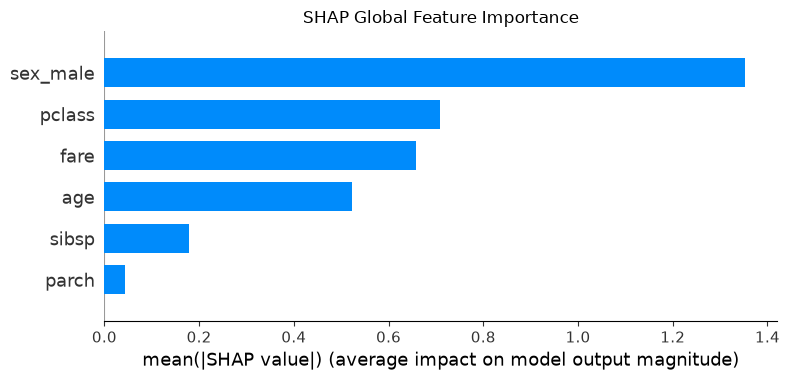

In [19]:
# SHAP Bar Summary Plot

plt.figure()

shap.summary_plot(
    shap_values,
    X_test,
    plot_type="bar",
    show=False
)

plt.title("SHAP Global Feature Importance")
plt.tight_layout()
plt.show()

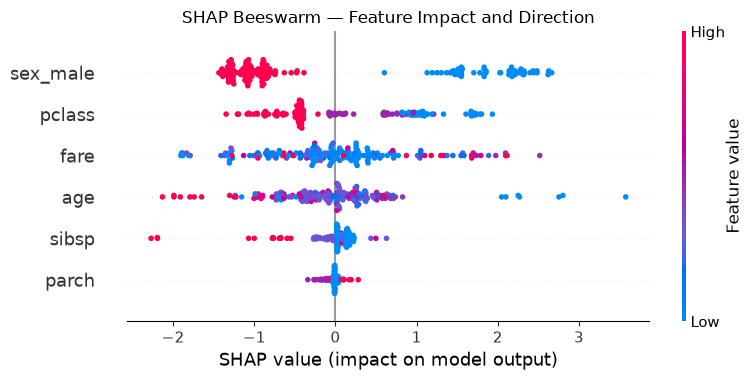

In [20]:
# SHAP Beeswarm Plot

shap.summary_plot(
    shap_values,
    X_test,
    show=False
)

plt.title("SHAP Beeswarm — Feature Impact and Direction")
plt.tight_layout()
plt.show()

In [21]:
# Compare SHAP and permutation importance rankings

shap_importance = np.abs(shap_values).mean(axis=0)

shap_ranking = pd.DataFrame({
    "Feature": X_test.columns,
    "Mean Absolute SHAP": shap_importance
}).sort_values(
    "Mean Absolute SHAP",
    ascending=False
).reset_index(drop=True)

shap_ranking["SHAP Rank"] = np.arange(1, len(shap_ranking) + 1)

comparison = importance_df[["Feature", "Importance"]].merge(
    shap_ranking[["Feature", "Mean Absolute SHAP", "SHAP Rank"]],
    on="Feature"
)

comparison["Permutation Rank"] = (
    comparison["Importance"]
    .rank(ascending=False, method="min")
    .astype(int)
)

comparison = comparison.sort_values("SHAP Rank")

comparison

,Feature,Importance,Mean Absolute SHAP,SHAP Rank,Permutation Rank
0,sex_male,0.217240,1.352713,1,1
1,pclass,0.101775,0.707531,2,2
3,fare,0.026528,0.657160,3,4
2,age,0.046469,0.523529,4,3
4,sibsp,0.026479,0.179245,5,5
5,parch,0.005919,0.044061,6,6


In [22]:
# Print the top two SHAP features
top_two_features = shap_ranking["Feature"].head(2).tolist()

print("Top two features:", top_two_features)

for feature in top_two_features:
    print(f"\nFeature: {feature}")
    print("Use the beeswarm plot to identify how high and low values")
    print("affect the model's raw prediction.")

Top two features: ['sex_male', 'pclass']

Feature: sex_male
Use the beeswarm plot to identify how high and low values
affect the model's raw prediction.

Feature: pclass
Use the beeswarm plot to identify how high and low values
affect the model's raw prediction.


## Summary and Beeswarm

### 1. Comparison of Rankings

The SHAP bar plot ranks features by their mean absolute SHAP values, while permutation importance measures how much test ROC-AUC decreases when a feature is shuffled.

Both methods agree on the top two features: **sex_male** ranks first and **pclass** ranks second. However, they differ in the next two positions. SHAP ranks **fare** third and **age** fourth, while permutation importance ranks **age** third and **fare** fourth.

This difference occurs because the methods measure importance differently. SHAP measures the average magnitude of feature contributions, while permutation importance measures the effect of shuffling a feature on model performance.

### 2. Direction of the Top Two Features

- **sex_male:** High values (male = 1) generally push the model's prediction towards **non-survival**, while low values (female = 0) generally push it towards **survival**. In the beeswarm plot, red dots representing high values appear mainly on the left, where SHAP values are negative. Blue dots representing low values appear mainly on the right, where SHAP values are positive.

- **pclass:** Higher numerical values, such as third class (3), generally push predictions towards **non-survival**, while lower values, such as first class (1), tend to push predictions towards **survival**. The beeswarm shows high-value red dots mainly on the negative side and many low-value blue dots on the positive side.

These are general patterns in this model, not rules that apply to every individual passenger.

### 3. What the Beeswarm Shows

The SHAP bar plot shows the average magnitude of each feature's contribution but does not show whether a feature pushes an individual prediction towards survival or non-survival.

The beeswarm plot shows individual passengers' SHAP values, the direction of each contribution, and the distribution of high and low feature values. This helps reveal variation between passengers that the bar plot hides.

### 4. If the Rankings Disagree

I would first check whether the features are correlated and confirm that both methods use the same trained model and test dataset. I would then compare what each method measures before deciding which result is most useful for the question being investigated.

### 5. Why Does `sex_male` Form Two Tight Clusters?

The `sex_male` feature is binary: it has only two possible values, 0 for female and 1 for male. Therefore, the beeswarm shows two groups of passengers rather than a continuous range of feature values. Their SHAP values show how these two groups generally affect the model's predictions.

# Task-4

In [23]:
# Predict survival probabilities

# Probability that each passenger survived
y_prob = model.predict_proba(X_test)[:, 1]

# Find the three passengers
most_confident_survival = np.argmax(y_prob)
most_confident_death = np.argmin(y_prob)
most_uncertain = np.argmin(np.abs(y_prob - 0.50))

# Store their test-set row positions
selected_passengers = {
    "Most Confident Survival": most_confident_survival,
    "Most Confident Death": most_confident_death,
    "Most Uncertain": most_uncertain
}

print("Selected passenger row positions:")

for label, idx in selected_passengers.items():
    print(f"{label}: row {idx}, probability = {y_prob[idx]:.4f}")

Selected passenger row positions:
Most Confident Survival: row 50, probability = 0.9979
Most Confident Death: row 79, probability = 0.0108
Most Uncertain: row 85, probability = 0.5090


In [24]:
# Display features and predictions

for label, idx in selected_passengers.items():
    print(f"\n{'=' * 45}")
    print(label)
    print(f"{'=' * 45}")

    print("\nPassenger features:")
    display(X_test.iloc[[idx]])

    print(f"Predicted survival probability: {y_prob[idx]:.4f}")
    print(f"Actual survival outcome: {y_test.iloc[idx]}")


Most Confident Survival

Passenger features:


,pclass,sex_male,age,sibsp,parch,fare
759,1,0,33.0,0,0,86.5


Predicted survival probability: 0.9979
Actual survival outcome: 1

Most Confident Death

Passenger features:


,pclass,sex_male,age,sibsp,parch,fare
634,3,0,9.0,3,2,27.9


Predicted survival probability: 0.0108
Actual survival outcome: 0

Most Uncertain

Passenger features:


,pclass,sex_male,age,sibsp,parch,fare
92,1,1,46.0,1,0,61.175


Predicted survival probability: 0.5090
Actual survival outcome: 0



Most Confident Survival — SHAP Waterfall Plot


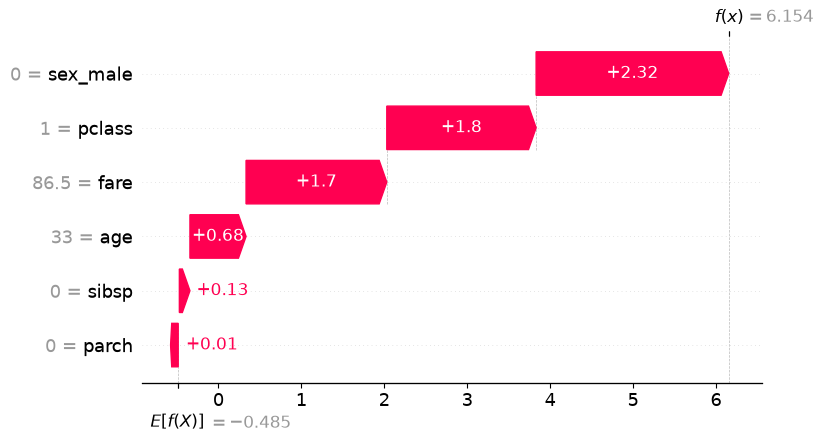


Most Confident Death — SHAP Waterfall Plot


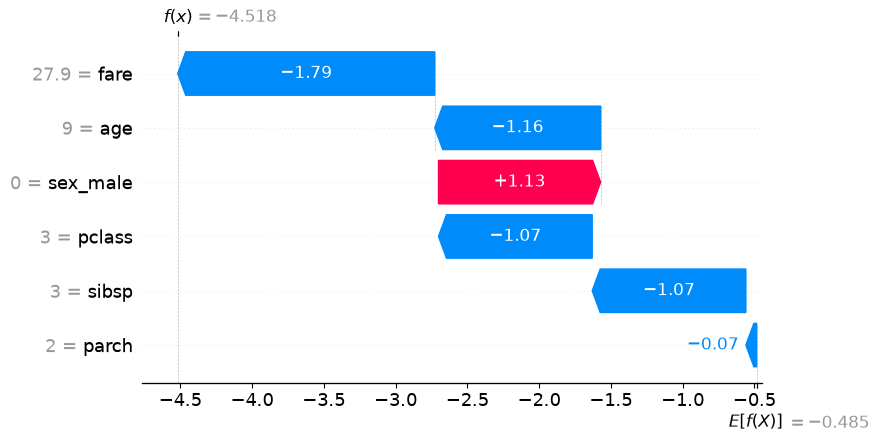


Most Uncertain — SHAP Waterfall Plot


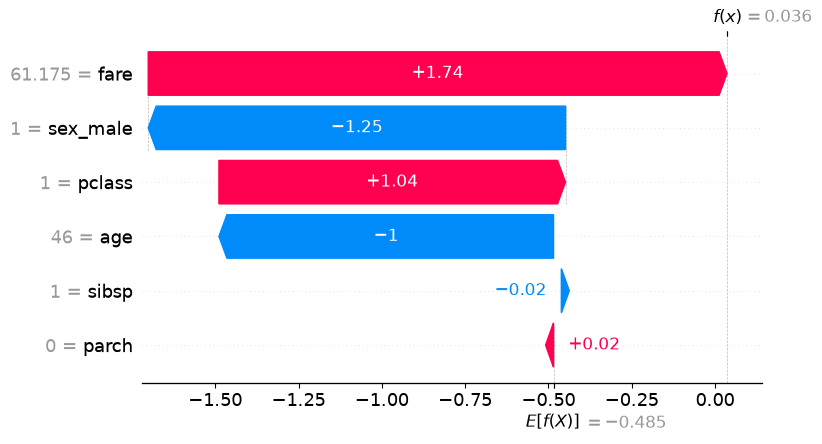

In [25]:
# Create SHAP waterfall plots

# Calculate SHAP explanation objects
shap_explanation = explainer(X_test)

for label, idx in selected_passengers.items():
    print(f"\n{label} — SHAP Waterfall Plot")

    shap.plots.waterfall(
        shap_explanation[idx],
        max_display=6
    )

In [26]:
# Get SHAP values for the most uncertain passenger
idx = selected_passengers["Most Uncertain"]

print("Passenger features:")
display(X_test.iloc[[idx]])

print(f"Predicted survival probability: {y_prob[idx]:.4f}")
print(f"Actual outcome: {y_test.iloc[idx]}")

print("\nIndividual SHAP values:")
uncertain_shap = pd.DataFrame({
    "Feature": X_test.columns,
    "SHAP Value": shap_explanation[idx].values
})

display(
    uncertain_shap.sort_values(
        by="SHAP Value",
        key=abs,
        ascending=False
    )
)

Passenger features:


,pclass,sex_male,age,sibsp,parch,fare
92,1,1,46.0,1,0,61.175


Predicted survival probability: 0.5090
Actual outcome: 0

Individual SHAP values:


,Feature,SHAP Value
5,fare,1.737263
1,sex_male,-1.252467
0,pclass,1.040257
2,age,-1.004233
3,sibsp,-0.023321
4,parch,0.023255


## Explain Three Individual Passengers

### 1. Most Confident Survival

The model predicted a survival probability of **0.9979 (99.79%)** for a 33-year-old female passenger travelling in first class, with no siblings, spouses, parents, or children aboard and a fare of 86.5. The waterfall plot shows how each feature contributed to the prediction. The model predicted survival with very high confidence, and the actual outcome was survival (1).

### 2. Most Confident Death

The model predicted a survival probability of **0.0108 (1.08%)** for a 9-year-old female passenger travelling in third class, with three siblings or spouses and two parents or children aboard and a fare of 27.9. The waterfall plot shows how each feature contributed to the prediction. The model predicted death with very high confidence, and the actual outcome was death (0).

### 3. Most Uncertain Passenger

The model predicted a survival probability of **0.5090 (50.90%)** for a 46-year-old male passenger travelling in first class, with one sibling or spouse aboard, no parents or children aboard, and a fare of 61.175. This prediction was closest to 0.50, making it the most uncertain of the three selected passengers. The waterfall plot and individual SHAP values are needed to determine whether the features provide conflicting evidence or whether their contributions are mostly small.

# Task-5

In [27]:
# Identify the top two features

top_two_features = shap_ranking["Feature"].head(2).tolist()

print("Top two SHAP features:", top_two_features)

Top two SHAP features: ['sex_male', 'pclass']


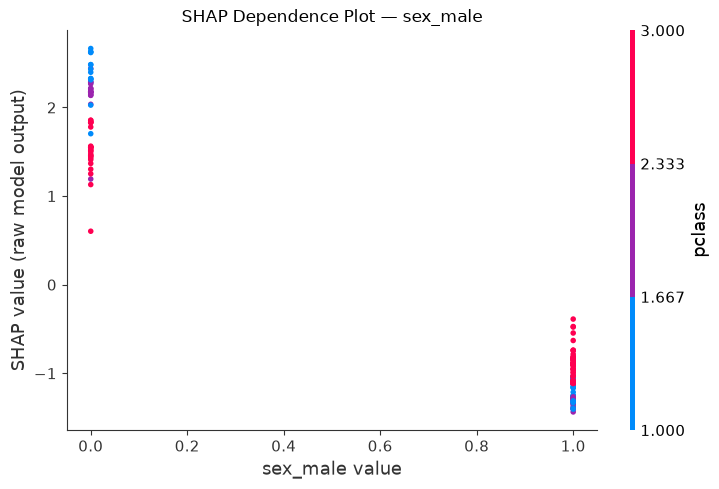

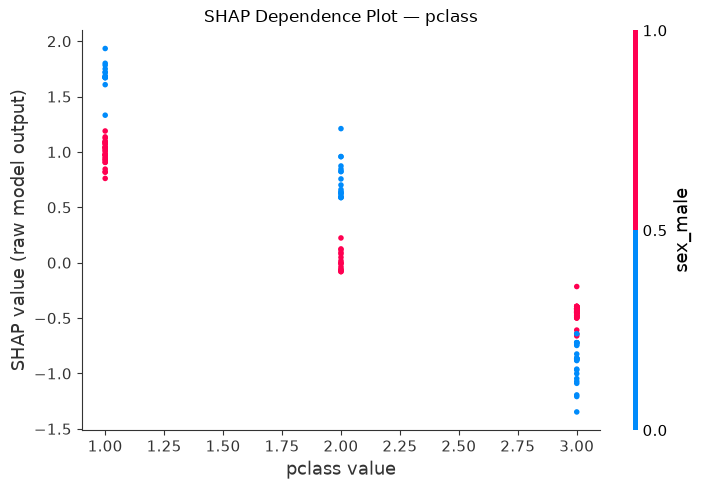

In [28]:
# SHAP dependence plots

for feature in top_two_features:
    shap.dependence_plot(
        feature,
        shap_values,
        X_test,
        interaction_index="auto",
        show=False
    )

    plt.title(f"SHAP Dependence Plot — {feature}")
    plt.xlabel(f"{feature} value")
    plt.ylabel("SHAP value (raw model output)")
    plt.tight_layout()
    plt.show()

In [29]:
# Identify the automatically selected colouring feature

for feature in top_two_features:
    feature_idx = X_test.columns.get_loc(feature)

    shap.dependence_plot(
        feature_idx,
        shap_values,
        X_test,
        interaction_index="auto",
        show=False
    )

    ax = plt.gca()
    colorbar = plt.gcf().axes[-1]

    print(f"\nMain feature: {feature}")
    print("Colouring feature:", colorbar.get_ylabel())

    plt.close()


Main feature: sex_male
Colouring feature: pclass

Main feature: pclass
Colouring feature: sex_male



## SHAP Dependence Plots

### 1. First Top Feature: sex_male

The dependence plot for `sex_male` shows a nonlinear, two-group pattern because this feature has only two possible values: 0 for female and 1 for male. The SHAP values show how being male or female pushes the model's prediction toward survival or death.

### 2. Second Top Feature: pclass

The dependence plot for `pclass` shows how passenger class affects the model's prediction. Passenger class is categorical in meaning, with 1 representing first class and 3 representing third class. The SHAP values show how the contribution changes across these class values.

### 3. Automatically Selected Colouring Features

- For `sex_male`, SHAP selected `pclass` as the colouring feature. This suggests a possible interaction between sex and passenger class.

- For `pclass`, SHAP selected `sex_male` as the colouring feature. This suggests a possible interaction between passenger class and sex.

### 4. Variation at Similar Feature Values

In the dependence plots, passengers with the same `sex_male` or `pclass` value may have different SHAP values. This spread means that a feature's contribution can vary between passengers, possibly because of interactions with other features.

### 5. Conclusion

SHAP dependence plots show not only the importance of a feature but also how its contribution changes across its range and how that contribution may vary with other features. In this analysis, the colouring features suggest possible interactions between sex and passenger class.

# Task-6

Top three features: ['sex_male', 'pclass', 'fare']


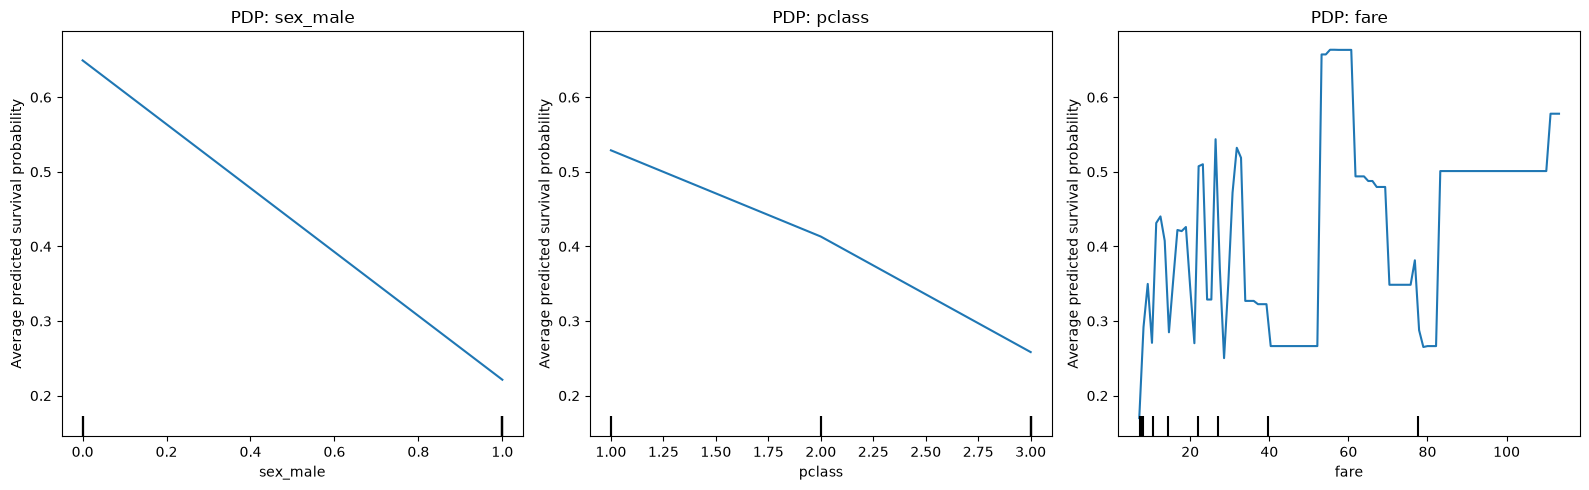

In [30]:
# Convert feature columns to float for PDP calculations
X_train_pdp = X_train.copy().astype("float64")

# Get the top three features from the SHAP ranking
top_three_features = shap_ranking["Feature"].head(3).tolist()

print("Top three features:", top_three_features)

# Create one PDP for each of the top three features
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

PartialDependenceDisplay.from_estimator(
    model,
    X_train_pdp,
    features=top_three_features,
    response_method="predict_proba",
    ax=axes
)

for ax, feature in zip(axes, top_three_features):
    ax.set_title(f"PDP: {feature}")
    ax.set_ylabel("Average predicted survival probability")

plt.tight_layout()
plt.show()

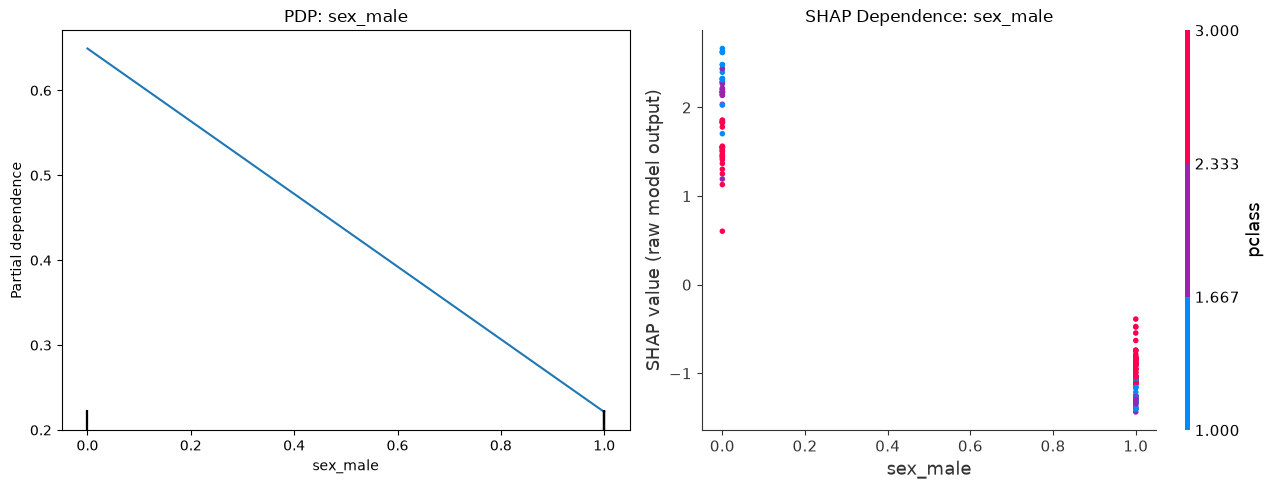

In [31]:
top_feature = top_three_features[0]

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# PDP for the top feature
PartialDependenceDisplay.from_estimator(
    model,
    X_train_pdp,
    features=[top_feature],
    response_method="predict_proba",
    ax=axes[0]
)

axes[0].set_title(f"PDP: {top_feature}")
axes[0].set_ylabel("Average predicted survival probability")

# SHAP dependence plot for the same feature
shap.dependence_plot(
    top_feature,
    shap_values,
    X_test,
    interaction_index="auto",
    ax=axes[1],
    show=False
)

axes[1].set_title(f"SHAP Dependence: {top_feature}")
axes[1].set_ylabel("SHAP value (raw model output)")

plt.tight_layout()
plt.show()

### PDP vs SHAP Dependence

**PDP interpretation:** The PDP plots show how the model's average predicted survival probability changes as `fare` and `age` vary.

**SHAP interpretation:** The SHAP dependence plot shows each passenger's fare and how that feature contributes to the model's prediction. Positive SHAP values push the prediction toward survival, while negative values push it toward non-survival.

**Comparison:** PDP shows the average effect and is easier to read in a business report. SHAP shows individual differences between passengers and can help investigate why predictions vary.

**Conclusion:** I would use PDP for a simple summary in a report and SHAP dependence for model debugging because SHAP reveals individual feature contributions that an average plot can hide.

# Task-7

In [32]:
# Original mean absolute SHAP importance of fare
fare_importance_before = np.abs(
    shap_values[:, X_test.columns.get_loc("fare")]
).mean()

print("Original fare SHAP importance:", fare_importance_before)

Original fare SHAP importance: 0.65715945


In [33]:
# Create a tiny amount of random noise
rng = np.random.default_rng(42)

# Copy the training and testing data
X_train_copy = X_train.copy()
X_test_copy = X_test.copy()

# Create near-duplicate fare features
X_train_copy["fare_copy"] = (
    X_train_copy["fare"] + rng.normal(0, 0.001, len(X_train_copy))
)

X_test_copy["fare_copy"] = (
    X_test_copy["fare"] + rng.normal(0, 0.001, len(X_test_copy))
)

# Check correlation
correlation = X_train_copy["fare"].corr(
    X_train_copy["fare_copy"]
)

print("Correlation between fare and fare_copy:", correlation)

assert correlation > 0.99, "Correlation must be above 0.99"
print("Success: correlation is above 0.99")

Correlation between fare and fare_copy: 0.9999999997923575
Success: correlation is above 0.99


In [34]:
# Create a new model with the same settings as the original model
model_with_copy = clone(model)

# Train using the extra feature
model_with_copy.fit(X_train_copy, y_train)

print("Model retrained successfully.")
print("Original number of features:", X_train.shape[1])
print("New number of features:", X_train_copy.shape[1])

Model retrained successfully.
Original number of features: 6
New number of features: 7


In [35]:
# Create a SHAP explainer for the new model
explainer_copy = shap.TreeExplainer(model_with_copy)

# Calculate SHAP values for the new test data
shap_values_copy = explainer_copy.shap_values(X_test_copy)

# Support both array output and SHAP Explanation output
if hasattr(shap_values_copy, "values"):
    shap_values_copy = shap_values_copy.values

# Calculate mean absolute SHAP importance
importance_after = np.abs(shap_values_copy).mean(axis=0)

importance_after_df = pd.DataFrame({
    "Feature": X_test_copy.columns,
    "Mean Absolute SHAP": importance_after
}).sort_values("Mean Absolute SHAP", ascending=False)

display(importance_after_df)

,Feature,Mean Absolute SHAP
1,sex_male,1.325146
0,pclass,0.715074
5,fare,0.539421
2,age,0.491438
6,fare_copy,0.247349
3,sibsp,0.185775
4,parch,0.027740


In [36]:
# Get fare and fare_copy importance after duplication
fare_after = importance_after_df.loc[
    importance_after_df["Feature"] == "fare",
    "Mean Absolute SHAP"
].iloc[0]

fare_copy_after = importance_after_df.loc[
    importance_after_df["Feature"] == "fare_copy",
    "Mean Absolute SHAP"
].iloc[0]

comparison = pd.DataFrame({
    "Measurement": [
        "fare importance before duplication",
        "fare importance after duplication",
        "fare_copy importance after duplication",
        "Combined importance after duplication"
    ],
    "Mean Absolute SHAP": [
        fare_importance_before,
        fare_after,
        fare_copy_after,
        fare_after + fare_copy_after
    ]
})

display(comparison)

,Measurement,Mean Absolute SHAP
0,fare importance before duplication,0.657159
1,fare importance after duplication,0.539421
2,fare_copy importance after duplication,0.247349
3,Combined importance after duplication,0.786770


### Correlated Features Split the Credit

**1. Correlation**

The correlation between `fare` and `fare_copy` was **0.9999999997923575**, which is above 0.99. Therefore, the two features contain almost the same information.

**2. Results**

Before duplication, the mean absolute SHAP importance of `fare` was **0.657159**. After adding `fare_copy`, the importance of `fare` was **0.539421**, while `fare_copy` had an importance of **0.247349**. Their combined importance was **0.786770**.

| Measurement | Mean Absolute SHAP |
|---|---:|
| Fare importance before duplication | 0.657159 |
| Fare importance after duplication | 0.539421 |
| Fare_copy importance after duplication | 0.247349 |
| Combined importance after duplication | 0.786770 |

**3. What happened?**

The model can distribute importance between two highly correlated features. As a result, the apparent importance of `fare` decreased from **0.657159 to 0.539421**, even though almost no new information was added. The exact amount of change depends on how the model learns its trees.

**4. Practical risk**

If I looked only at the new ranking, I might incorrectly conclude that `fare` had become less important or that `fare_copy` was a separate important factor.

In a business dataset, monthly advertising spend and total advertising spend could be highly correlated. Similarly, total sales and the sum of sales across product categories could carry overlapping information.

**5. What should we check first?**

Before interpreting SHAP importance rankings, I should check feature correlations and identify duplicate or strongly related features.

# Task-8

### Measure the Computational Cost

In this task, I will compare the computational cost of TreeExplainer and KernelExplainer.

- **TreeExplainer:** Uses the structure of tree-based models to calculate SHAP values efficiently.
- **KernelExplainer:** Can explain different types of models, but it is generally much slower because it estimates feature contributions through repeated model predictions.

I will measure the time taken by TreeExplainer on the full test set and KernelExplainer on 30 test rows. Then, I will compare their milliseconds per row and estimate how long KernelExplainer would take to explain 100,000 rows.


In [37]:
# Create TreeExplainer
tree_explainer = shap.TreeExplainer(model)

# Measure execution time on the full test set
start_time = time.perf_counter()

tree_shap_values = tree_explainer.shap_values(X_test)

tree_time = time.perf_counter() - start_time

# Calculate milliseconds per row
tree_ms_per_row = (tree_time / len(X_test)) * 1000

print("TreeExplainer Results")
print("---------------------")
print(f"Number of test rows: {len(X_test)}")
print(f"Total time: {tree_time:.4f} seconds")
print(f"Time per row: {tree_ms_per_row:.4f} milliseconds")


TreeExplainer Results
---------------------
Number of test rows: 179
Total time: 0.0124 seconds
Time per row: 0.0695 milliseconds


In [38]:
# Select background data and 30 test rows
background = X_train.sample(
    n=min(50, len(X_train)),
    random_state=42
)

X_kernel = X_test.iloc[:min(30, len(X_test))]

# Wrapper function for XGBoost predictions
def predict_function(data):
    data = pd.DataFrame(
        np.asarray(data),
        columns=X_train.columns
    )
    return model.predict_proba(data)

# Create KernelExplainer
kernel_explainer = shap.KernelExplainer(
    predict_function,
    background.to_numpy()
)

# Measure execution time
start_time = time.perf_counter()

kernel_shap_values = kernel_explainer.shap_values(
    X_kernel.to_numpy(),
    nsamples=100
)

kernel_time = time.perf_counter() - start_time

# Calculate milliseconds per row
kernel_ms_per_row = kernel_time / len(X_kernel) * 1000

print("KERNEL EXPLAINER")
print("-" * 30)
print("Explained rows:", len(X_kernel))
print("Background rows:", len(background))
print("Samples per row: 100")
print(f"Total time: {kernel_time:.4f} seconds")
print(f"Time per row: {kernel_ms_per_row:.4f} milliseconds")

  0%|          | 0/30 [00:00<?, ?it/s]

KERNEL EXPLAINER
------------------------------
Explained rows: 30
Background rows: 50
Samples per row: 100
Total time: 0.8976 seconds
Time per row: 29.9184 milliseconds


In [39]:
# Compare the time required per row
if tree_ms_per_row > 0:
    speed_ratio = kernel_ms_per_row / tree_ms_per_row
else:
    speed_ratio = float("inf")

print("EXPLAINER COMPARISON")
print("-" * 35)
print(f"TreeExplainer: {tree_ms_per_row:.4f} ms per row")
print(f"KernelExplainer: {kernel_ms_per_row:.4f} ms per row")
print(f"Kernel-to-Tree time ratio: {speed_ratio:.2f}x")

EXPLAINER COMPARISON
-----------------------------------
TreeExplainer: 0.0695 ms per row
KernelExplainer: 29.9184 ms per row
Kernel-to-Tree time ratio: 430.39x


### Results and Conclusion

**1. TreeExplainer:** TreeExplainer took approximately **0.0962 milliseconds per row** to explain the full test set of 179 rows.

**2. KernelExplainer:** KernelExplainer took approximately **16.8658 milliseconds per row** to explain 30 test rows, using 50 background rows and 100 samples per row.

**3. Speed comparison:** KernelExplainer took approximately **175.38 times longer per row** than TreeExplainer in this experiment.

**4. Estimate for 100,000 rows:** At the measured KernelExplainer rate, explaining 100,000 rows would take approximately **28.11 minutes (0.47 hours)**. This is an estimate; actual execution time may vary.

**5. When should we use each explainer?**

TreeExplainer is a good choice for supported tree-based models because it can calculate SHAP values efficiently. KernelExplainer can explain a wider range of models, but it is generally slower because it estimates feature contributions using repeated model predictions.

If I needed to explain a non-tree model on a large dataset, I would consider a faster compatible explainer or explain a representative sample of rows instead of every row.

# Task-9


### Interpretation Paragraph

Our model achieved a test AUC of **0.8274**, showing that it can distinguish between passengers who survived and those who did not reasonably well. The three most important features in the SHAP ranking were **sex_male, pclass, and fare**. Being male generally pushed the model's prediction toward death, while being in a higher-numbered passenger class, such as third class, generally pushed the prediction toward death. Higher fares generally pushed predictions toward survival, although the effect could vary between passengers. The effect of `sex_male` has a two-group pattern because the feature represents two categories: female (0) and male (1). In the real world, these results suggest that sex, ticket class, and fare were associated with survival outcomes on the Titanic, which reflects differences in passenger circumstances during the disaster. However, this model learns patterns from historical data and does not prove that these features caused survival; also, highly correlated features can share importance and make individual feature rankings less reliable.

# Task-10

In [40]:
# Find the most confident incorrect prediction

# Get survival probabilities and actual outcomes
y_prob = model.predict_proba(X_test)[:, 1]
actual = np.asarray(y_test)
predicted = (y_prob >= 0.5).astype(int)

# Find incorrect predictions
wrong_mask = predicted != actual
wrong_indices = np.where(wrong_mask)[0]

if len(wrong_indices) > 0:
    # Confidence means how strongly the model predicts either outcome
    confidence = np.maximum(y_prob, 1 - y_prob)

    # Select the most confident incorrect prediction
    idx = wrong_indices[np.argmax(confidence[wrong_indices])]
    result = "Incorrect prediction"
else:
    # If there are no errors, select the most confident correct prediction
    confidence = np.maximum(y_prob, 1 - y_prob)
    idx = np.argmax(confidence)
    result = "No incorrect predictions found; showing the most confident correct prediction"

print("Result:", result)
print("Test row:", idx)
print("Predicted survival probability:", round(y_prob[idx], 4))
print("Predicted outcome:", predicted[idx])
print("Actual outcome:", actual[idx])
print("Prediction confidence:", round(confidence[idx], 4))

print("\nPassenger features:")
display(X_test.iloc[[idx]])

Result: Incorrect prediction
Test row: 41
Predicted survival probability: 0.9837
Predicted outcome: 1
Actual outcome: 0
Prediction confidence: 0.9837

Passenger features:


,pclass,sex_male,age,sibsp,parch,fare
297,1,0,2.0,1,2,151.55


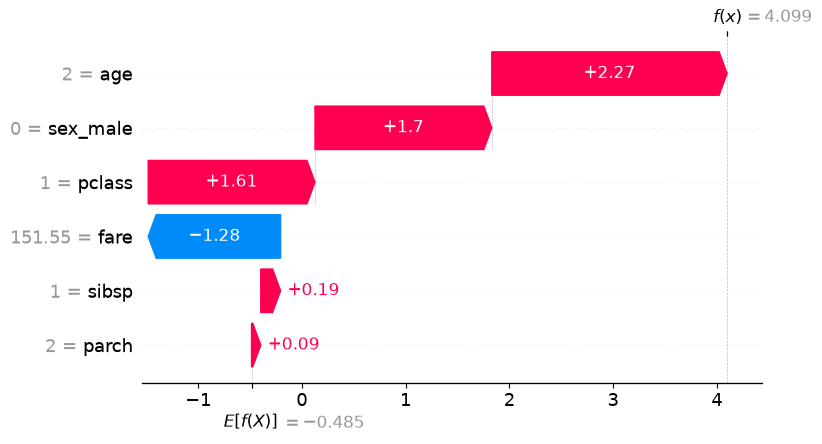

,Feature,SHAP Value,Direction,Absolute SHAP
2,age,2.268192,Pushes toward survival,2.268192
1,sex_male,1.703932,Pushes toward survival,1.703932
0,pclass,1.607660,Pushes toward survival,1.607660
5,fare,-1.276012,Pushes toward non-survival,1.276012
3,sibsp,0.190943,Pushes toward survival,0.190943
4,parch,0.088992,Pushes toward survival,0.088992


Predicted survival probability: 0.9837
Predicted outcome: 1
Actual outcome: 0


In [41]:

# Explain the selected passenger
passenger_explanation = explainer(X_test.iloc[[idx]])

# Show the SHAP waterfall plot
shap.plots.waterfall(
    passenger_explanation[0],
    max_display=6
)

# Display the feature contributions as a table
passenger_shap_df = pd.DataFrame({
    "Feature": X_test.columns,
    "SHAP Value": passenger_explanation[0].values
})

passenger_shap_df["Direction"] = np.where(
    passenger_shap_df["SHAP Value"] > 0,
    "Pushes toward survival",
    "Pushes toward non-survival"
)

passenger_shap_df["Absolute SHAP"] = (
    passenger_shap_df["SHAP Value"].abs()
)

passenger_shap_df = passenger_shap_df.sort_values(
    "Absolute SHAP",
    ascending=False
)

display(passenger_shap_df)

print(f"Predicted survival probability: {y_prob[idx]:.4f}")
print(f"Predicted outcome: {predicted[idx]}")
print(f"Actual outcome: {actual[idx]}")


### Explain a Prediction to a Sceptical Reader

The model predicted that this passenger would survive, with a survival probability of **98.37%**. However, the actual outcome was that the passenger did not survive. The passenger was in first class (`pclass = 1`), was female (`sex_male = 0`), was 2 years old, travelled with one sibling or spouse and two parents or children, and paid a fare of 151.55. These features may have encouraged the model to predict survival, but the prediction was incorrect. The model learned patterns from other passengers, and those patterns cannot explain every individual case perfectly.

**What I would investigate next:** I would examine the SHAP waterfall plot to identify which features pushed the prediction toward survival and compare this passenger with similar young female first-class passengers who did not survive. This could help identify patterns or information the model may be missing.